In [46]:
import pandas as pd
import numpy as np

In [47]:
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer

In [48]:
df = pd.read_csv('train.csv', usecols = ['Age', 'Fare', 'Survived', 'SibSp', 'Parch'])
df['family'] = df['SibSp'] + df['Parch']

In [49]:
df.dropna(inplace = True)

In [50]:
df.shape

(714, 6)

In [51]:
df.head()

,Survived,Age,SibSp,Parch,Fare,family
0,0,22.0,1,0,7.2500,1
1,1,38.0,1,0,71.2833,1
2,1,26.0,0,0,7.9250,0
3,1,35.0,1,0,53.1000,1
4,0,35.0,0,0,8.0500,0


In [52]:
X  = df.iloc[:,1:]
y = df.iloc[:,0]

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.head(2)

,Age,SibSp,Parch,Fare,family
328,31.0,1,1,20.5250,2
73,26.0,1,0,14.4542,1


In [54]:
clf = DecisionTreeClassifier()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
accuracy_score(y_test, y_pred)

0.6363636363636364

In [55]:
np.mean(cross_val_score(DecisionTreeClassifier(), X, y, cv=10, scoring='accuracy'))

np.float64(0.6554968701095462)

In [56]:
kbin_age = KBinsDiscretizer(n_bins=10, encode='ordinal', strategy='quantile')
kbin_fare = KBinsDiscretizer(n_bins=10, encode='ordinal', strategy='quantile')

In [57]:
trf  = ColumnTransformer([
    ('first', kbin_age, ['Age']),
    ('second', kbin_fare, ['Fare'])
])

In [58]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)


In [59]:
trf.named_transformers_

{'first': KBinsDiscretizer(encode='ordinal', n_bins=10),
 'second': KBinsDiscretizer(encode='ordinal', n_bins=10),
 'remainder': 'drop'}

In [60]:
trf.named_transformers_['first'].bin_edges_

array([array([ 0.42, 14.  , 19.  , 22.  , 25.  , 28.5 , 32.  , 36.  , 42.  ,
              50.  , 80.  ])                                                ],
      dtype=object)

In [61]:
output = pd.DataFrame({
    'age': X_train['Age'],
    'age_trf': X_train_trf[:,0],
    'fare': X_train['Fare'],
    'fare_trf': X_train_trf[:,1]
})

In [62]:
output['age_labels'] = pd.cut(
    output['age'],
    bins=trf.named_transformers_['first'].bin_edges_[0].tolist()

)

output['fare_labels'] = pd.cut(
    output['fare'],
    bins=trf.named_transformers_['second'].bin_edges_[0].tolist()

)

In [63]:
output.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
289,22.0,3.0,7.7500,1.0,"(19.0, 22.0]","(0.0, 7.75]"
571,53.0,9.0,51.4792,8.0,"(50.0, 80.0]","(29.125, 51.479]"
145,19.0,2.0,36.7500,7.0,"(14.0, 19.0]","(29.125, 51.479]"
462,47.0,8.0,38.5000,7.0,"(42.0, 50.0]","(29.125, 51.479]"
683,14.0,1.0,46.9000,7.0,"(0.42, 14.0]","(29.125, 51.479]"


In [64]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf, y_train)
y_pred2 = clf.predict(X_test_trf)

accuracy_score(y_test, y_pred2)


0.6223776223776224

In [65]:
X_trf = trf.fit_transform(X)
np.mean(cross_val_score(DecisionTreeClassifier(), X_trf, y, cv=10, scoring='accuracy'))

np.float64(0.682140062597809)

In [66]:
#discretize fun

def discretize(bins , strategy):
   kbin_age = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)
   kbin_fare = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)

   trf = ColumnTransformer([
       ('first', kbin_age, ["Age"]),
       ('second', kbin_fare, ["Fare"])
   ])

   X_trf = trf.fit_transform(X)
   accuracy = np.mean(cross_val_score(DecisionTreeClassifier(), X_trf, y, cv=10, scoring='accuracy'))

   plt.figure(figsize=(14,10))
   plt.subplot(121)
   plt.hist(X['Age'])
   plt.title("Original Age Distribution")

   plt.subplot(122)
   plt.hist(X_trf[:,0], color='red')
   plt.title(f"Transformed Age Distribution (Strategy: {strategy})")
   plt.show()

   plt.figure(figsize=(14,10))
   plt.subplot(121)
   plt.hist(X['Fare'])
   plt.title("Original Fare Distribution")

   plt.subplot(122)
   plt.hist(X_trf[:,1], color='red')
   plt.title(f"Transformed Fare Distribution (Strategy: {strategy})")
   plt.show()

   return trf

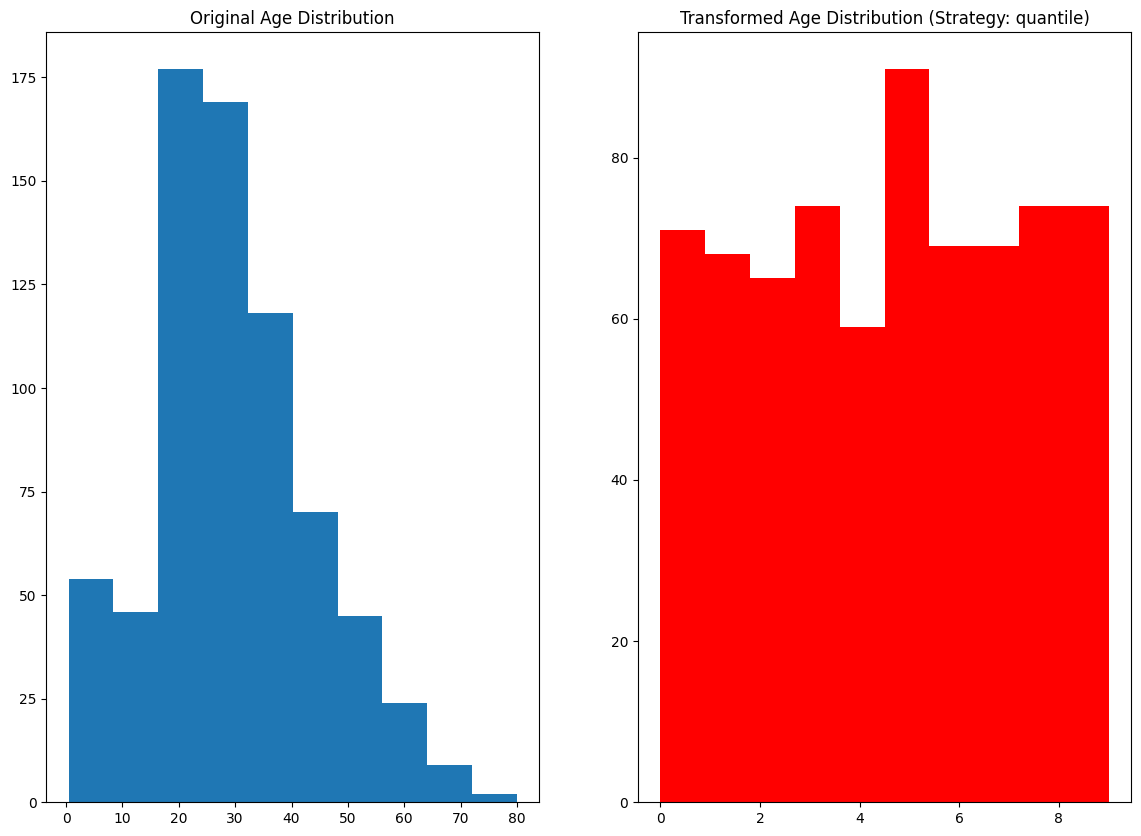

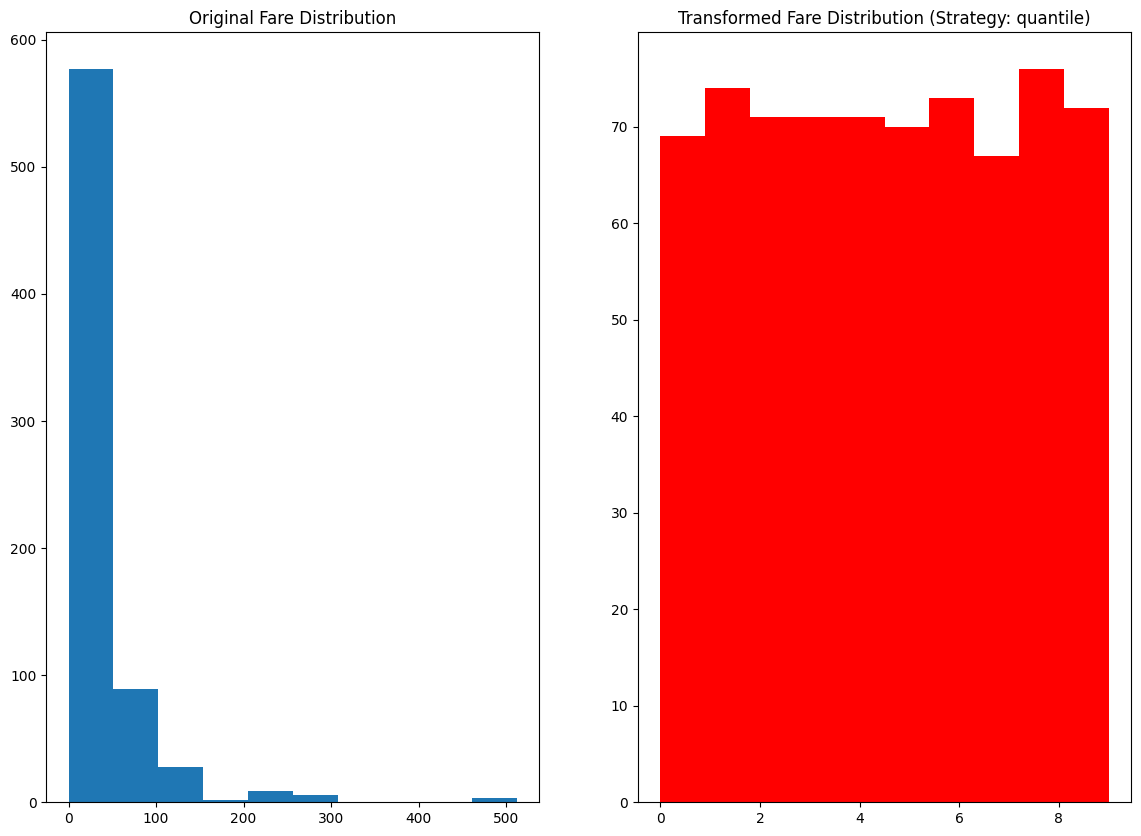

ColumnTransformer(transformers=[('first',
                                 KBinsDiscretizer(encode='ordinal', n_bins=10),
                                 ['Age']),
                                ('second',
                                 KBinsDiscretizer(encode='ordinal', n_bins=10),
                                 ['Fare'])])

In [67]:
discretize(10, 'quantile')

# **Binarization**

In [68]:
#without binarization


clf = DecisionTreeClassifier()

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

accuracy_score(y_test, y_pred)

0.6363636363636364

In [69]:
np.mean(cross_val_score(DecisionTreeClassifier(), X, y, cv=10, scoring='accuracy'))

np.float64(0.6471048513302036)

In [70]:
#with binarization

from sklearn.preprocessing import Binarizer

In [71]:
trf= ColumnTransformer([
    ('bin', Binarizer(copy=False), [' family'])
], remainder='passthrough')


In [72]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

ValueError: A given column is not a column of the dataframe